# Data Science Screening Exercise

## Introduction
We have been approached by a European bank that is looking to improve their Anti Money Laundering (AML) compliance, since they have been fined by the regulator for money laundering activity they weren't able to detect. They have approached ThetaRay to test the solution and have provided about 6 years of data (see details on the data sources and fields below). Your goal as the applied data scientist is to design the methodology and implement a machine learning solution to help the client.

Our strategy is to analyze **client activity per month**. The solution will run once a month, at the beginning of the month, and analyze the past month's activity. We will build a data frame of features that help detect abnormal client activity that might indicate money laundering. Ideally, the activity we find will not be detected by the systems currently in place.

No AML expertise is expected: we are assessing your data science skills (data quality, feature engineering, modelling and validation).

## Rules and timing

* You have **2 hours**. Suggested split: Part 1 ~45 min, Part 2 ~25 min, Part 3 ~35 min, and ~15 min to tidy up.
* **AI tools (ChatGPT, Copilot, Claude, etc.) are allowed.** You are responsible for everything in your notebook. In the follow-up session you will be asked to explain your decisions, your results and any line of code.
* We value **correct reasoning and clearly stated assumptions** over volume of code. A short, correct analysis beats a long, generic one.
* Submit the notebook **with all cell outputs**, so we can see your results exactly as you saw them.

## Data

We will use an anonymized data set from a bank in Europe covering 2018 to 2023. Six tables are provided and are loaded as pandas data frames:

| Variable | File | Description |
|:--|:--|:--|
| accounts | accounts.csv (4,500 rows) | Each record describes static characteristics of an account. |
| clients | clients.csv (4,500 rows) | Each record describes characteristics of a client. |
| client_accounts | client_accounts.csv (4,500 rows) | Each record links a client to an account. |
| standing_orders | standing_orders.csv (6,471 rows) | Each record describes a standing payment order of an account. |
| transactions | transactions.csv (1,027,938 rows) | Each record describes one transaction on an account. |
| fx_rates | fx_rates.csv (142 rows) | Monthly exchange rates. |

### Data source relations

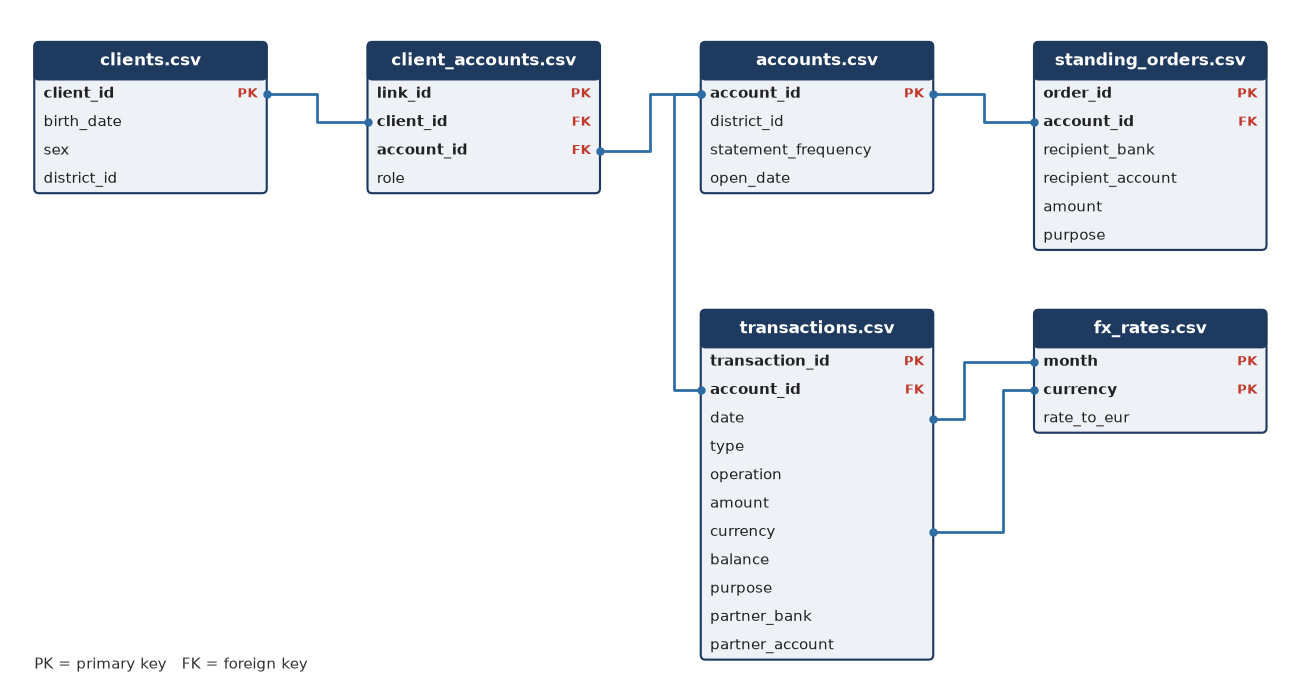

### Data dictionary

Dates are strings in `YYYY-MM-DD` format.

**accounts**

| Column | Type | Description |
|:--|:--|:--|
| `account_id` | integer | Account identifier (primary key) |
| `district_id` | integer | District of the account's branch |
| `statement_frequency` | text | How often statements are issued: `MONTHLY`, `WEEKLY` or `AFTER_TRANSACTION` |
| `open_date` | date | Date the account was opened |

**clients**

| Column | Type | Description |
|:--|:--|:--|
| `client_id` | integer | Client identifier (primary key) |
| `birth_date` | date | Client's date of birth |
| `sex` | text | `F` or `M` |
| `district_id` | integer | District of the client's address |

**client_accounts**

| Column | Type | Description |
|:--|:--|:--|
| `link_id` | integer | Link identifier (primary key) |
| `client_id` | integer | Client (foreign key to `clients`) |
| `account_id` | integer | Account (foreign key to `accounts`) |
| `role` | text | Role of the client on the account: `OWNER` |

**standing_orders**

| Column | Type | Description |
|:--|:--|:--|
| `order_id` | integer | Order identifier (primary key) |
| `account_id` | integer | Account the order is paid from (foreign key to `accounts`) |
| `recipient_bank` | text | Bank of the recipient (code) |
| `recipient_account` | integer | Account of the recipient |
| `amount` | decimal | Amount of the order |
| `purpose` | text | `INSURANCE`, `HOUSEHOLD` (household bills), `LEASING` or `LOAN_PAYMENT` |

**transactions**

| Column | Type | Description |
|:--|:--|:--|
| `transaction_id` | integer | Transaction identifier (primary key) |
| `account_id` | integer | Account (foreign key to `accounts`) |
| `date` | date | Date of the transaction |
| `type` | text | `CREDIT` (money in) or `DEBIT` (money out) |
| `operation` | text | `CASH_DEPOSIT`, `CASH_WITHDRAWAL`, `CARD_WITHDRAWAL`, `TRANSFER_IN` (from another bank) or `TRANSFER_OUT` (to another bank); empty for interest and fees |
| `amount` | decimal | Amount of the transaction |
| `currency` | text | Transaction currency: `EUR`, `USD` or `GBP` |
| `balance` | decimal | Account balance after the transaction |
| `purpose` | text | `INSURANCE`, `STATEMENT_FEE`, `INTEREST`, `PENALTY_INTEREST` (interest on a negative balance), `HOUSEHOLD`, `PENSION` or `LOAN_PAYMENT` |
| `partner_bank` | text | Bank of the counterparty (code), for transfers |
| `partner_account` | integer | Account of the counterparty, for transfers |

**fx_rates**

| Column | Type | Description |
|:--|:--|:--|
| `month` | text (`YYYY-MM`) | Month the rate applies to |
| `currency` | text | `USD` or `GBP` |
| `rate_to_eur` | decimal | EUR per 1 unit of `currency` (monthly average) |

## Background

Money laundering is the process of making money from crime look legitimate. It typically shows up in transaction data as activity that doesn't fit a client's normal behaviour: sudden changes in volume, unusual use of cash, or money that passes through an account without staying. You don't need any AML knowledge for this exercise.

First, run the next cell to load the data:

In [ ]:
# run this cell first
import pandas as pd

DATA_DIR = "data_v7"  # folder (or URL) containing the exercise .csv files

accounts = pd.read_csv(f"{DATA_DIR}/accounts.csv")
clients = pd.read_csv(f"{DATA_DIR}/clients.csv")
client_accounts = pd.read_csv(f"{DATA_DIR}/client_accounts.csv")
standing_orders = pd.read_csv(f"{DATA_DIR}/standing_orders.csv")
transactions = pd.read_csv(f"{DATA_DIR}/transactions.csv")
fx_rates = pd.read_csv(f"{DATA_DIR}/fx_rates.csv")

# Start of the Exercise

## Part 1: Fix the colleague's feature pipeline (~45 min)

A colleague wrote the first draft of the pipeline that builds the monthly client feature table (one row per client-month). No model has been trained yet. The code runs without errors, but it contains **at least 5 issues** affecting data quality, joins and feature engineering.

1. Run the cell and explore the data as much as you need.
2. Find and fix the issues. **Not every feature in the draft is worth keeping**: fix, replace or drop features as you see fit, and say why.
3. For each issue, fill in a row of the table below and add a cell that **demonstrates it with the data** (counts, a before/after comparison, a plot, etc.).

| # | Issue | Evidence (refer to your cell) | Fix |
|:--|:--|:--|:--|
| 1 | | | |
| 2 | | | |
| ... | | | |

In [ ]:
# ---- Colleague's draft: monthly client feature table (no model yet) ----
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder

# map every transaction to its client
df = transactions.merge(client_accounts[["account_id", "client_id"]], on="account_id")

# add the account's standing orders (for committed_out_share)
df = df.merge(
    standing_orders[["account_id", "amount"]].rename(columns={"amount": "order_amount"}),
    on="account_id",
    how="left",
)

df["month"] = pd.to_datetime(df["date"]).dt.to_period("M")

# credits are positive, debits negative
direction = {"CREDIT": 1, "DEBIT": -1}
df["signed_amount"] = df["amount"] * df["type"].map(direction)
df["amount_in"] = df["signed_amount"].clip(lower=0)
df["amount_out"] = (-df["signed_amount"]).clip(lower=0)

# the model needs numbers, so encode the operation type
df["operation_code"] = LabelEncoder().fit_transform(df["operation"].fillna("UNKNOWN"))

monthly = df.groupby(["client_id", "month"]).agg(
    total_in=("amount_in", "sum"),
    total_out=("amount_out", "sum"),
    main_operation=("operation_code", "median"),
    committed_out=("order_amount", "sum"),
).reset_index()

# share of the month's outflow that is committed by standing orders
monthly["committed_out_share"] = (monthly["committed_out"] / monthly["total_out"].where(monthly["total_out"] > 0)).fillna(0)

# how long the client has been with the bank
open_date = pd.to_datetime(client_accounts.set_index("client_id")["account_id"].map(accounts.set_index("account_id")["open_date"]))
monthly["account_age_days"] = (pd.Timestamp.today().normalize() - monthly["client_id"].map(open_date)).dt.days

# spending profile: group client-months by how much money goes in and out
kmeans = KMeans(n_clusters=5, n_init=10, random_state=0)
monthly["spending_cluster"] = kmeans.fit_predict(monthly[["total_in", "total_out"]])

features = ["total_in", "total_out", "main_operation", "committed_out_share", "account_age_days", "spending_cluster"]
monthly[features].describe()

In [ ]:
# Your fixes: add cells demonstrating each issue

## Part 2: Complete the feature set (~25 min)

Starting from your fixed pipeline, add **at least 2 new features** of your own. At least 2 of your final features must be derived from categorical fields. Then describe all your final features:

| Feature | Description | Source table(s) and field(s) | Derived from a categorical field? | When it could raise a false alert |
|:--|:--|:--|:--|:--|
| | | | | |

In [ ]:
# Start working here
# create new cells as required

## Part 3: Train a model and analyze the results (~35 min)

1. **Model.** Choose an anomaly detection model and explain why it suits this problem (2-3 sentences).
2. **Train** it on your final features.
3. **Results.** List the 20 most anomalous clients of the **latest monthly run**.
4. **Explain one** of them in 3-5 sentences, with supporting numbers: which features drove its score (compared with the client's own history and with other clients), and whether you would send it to an analyst or treat it as a likely false positive.

In [ ]:
# Start working here
# create new cells as required